# 6. Capillary rise and imbibition

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1–3 and 5

Dip a thin glass tube into water and the water climbs up it. Touch a paper towel to
a spill and the liquid is drawn into the paper. Both are driven by the same thing:
the solid prefers to be wet, so the system lowers its free energy by covering more
of the solid with liquid. Both are slowed by the same thing: the liquid has to flow
through narrow channels, and viscous friction grows with the length that has been
filled.

This is the first problem of Part II, and the simplest one in which the recipe of
the book produces a result that is used every day in laboratories: the
Lucas–Washburn law $h \propto \sqrt t$ and the approach to Jurin's equilibrium height.
It needs one slow variable, the height of the column, and both functions come
straight from the tables of Chapter 3.

The checks are the exact solution of the kinetic equation, the energy balance, and
a comparison with a model that includes the inertia of the liquid, which shows
where the description of this book stops being valid.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle
from scipy.integrate import solve_ivp

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## 6.1 The two functions

A vertical tube of radius $a$ dips into a large bath of liquid of density $\rho$,
viscosity $\eta$ and surface tension $\gamma$. The liquid wets the wall with contact
angle $\theta < 90^\circ$. Let $h(t)$ be the height of the liquid column above the
level of the bath.

*Slow variable.* One: $h$. The liquid is incompressible, so its mean velocity in the
tube is $\dot h$ at every height. As in Section 3.5, the constraint has been used by
elimination.

*Free energy: the wall.* When the column rises by $dh$, a band of wall of area
$2\pi a\,dh$ that was in contact with vapour is now in contact with liquid. The
interfacial energy changes by $(\gamma_{SL} - \gamma_{SV})\,2\pi a\,dh$, where
$\gamma_{SL}$ and $\gamma_{SV}$ are the solid–liquid and solid–vapour tensions.
Young's law, $\gamma_{SV} - \gamma_{SL} = \gamma\cos\theta$, turns this into
$-2\pi a\gamma\cos\theta\,dh$. The meniscus only moves; its area does not change.

*Free energy: gravity.* The column has mass $\rho\pi a^2h$ and its centre of mass is
at $h/2$, so its potential energy is $\tfrac12\pi a^2\rho g h^2$.

Together,

$$ A(h) = -2\pi a\gamma\cos\theta\;h + \tfrac12\pi a^2\rho g\,h^2 . \tag{6.1} $$

The wall pulls with the constant force $2\pi a\gamma\cos\theta$; gravity pushes back
with a force that grows with the height. The minimum of $A$ is at

$$ h_J = \frac{2\gamma\cos\theta}{\rho g a} , \tag{6.2} $$

Jurin's law: the equilibrium height is inversely proportional to the radius of the
tube. With $H = h/h_J$ the free energy takes the universal form
$A = \pi a^2\rho g h_J^2\,(\tfrac12H^2 - H)$.

*Dissipation function.* The liquid flows along a tube. From the third table of
Section 3.2, a Poiseuille flow with mean velocity $\bar v$ dissipates energy at the
rate $8\pi\eta\bar v^2$ per unit length, whatever the radius. Here $\bar v = \dot h$
over the filled length $h$:

$$ \Phi = \tfrac12\cdot 8\pi\eta\,\dot h^2\cdot h = 4\pi\eta\,h\,\dot h^2 . \tag{6.3} $$

The friction coefficient $8\pi\eta h$ grows with the height: the longer the column,
the more liquid must be dragged along to raise the meniscus by the same amount.

Equation (6.3) assumes that the flow is a Poiseuille flow along the whole column.
That is not true within a distance of the order of $a$ from the meniscus, nor near
the entrance of the tube, so the result will hold for $h \gg a$. It also neglects any
dissipation at the moving contact line, which is the subject of Exercise 4.

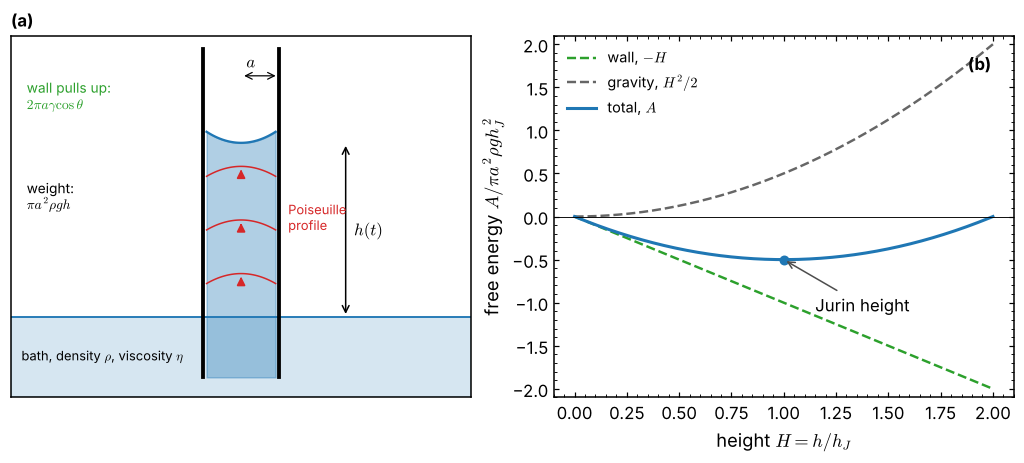

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 4.1))

# (a) schematic: bath, tube, column with a meniscus, Poiseuille profile
ax1.add_patch(Rectangle((-2.2, -1.2), 4.4, 1.2, color="C0", alpha=0.18))
ax1.plot([-2.2, 2.2], [0, 0], color="C0", lw=1.2)
for xw in (-0.36, 0.36):
    ax1.plot([xw, xw], [-0.9, 4.0], "k-", lw=2.5)
hcol = 2.6
xs = np.linspace(-0.33, 0.33, 100)
meniscus = hcol + 0.5 * (xs / 0.33) ** 2 * 0.33
ax1.fill_between(xs, -0.9, meniscus, color="C0", alpha=0.35)
ax1.plot(xs, meniscus, color="C0", lw=1.5)
for zz in (0.5, 1.3, 2.1):
    prof = 0.33 * (1 - (xs / 0.33) ** 2)
    ax1.plot(xs, zz + 0.45 * prof, color="C3", lw=1)
    ax1.annotate("", xy=(0, zz + 0.45 * 0.33), xytext=(0, zz), arrowprops=dict(arrowstyle="-|>", color="C3", lw=1.2))
ax1.annotate("", xy=(1.0, hcol), xytext=(1.0, 0), arrowprops=dict(arrowstyle="<->", color="k"))
ax1.text(1.08, hcol / 2, "$h(t)$", va="center")
ax1.annotate("", xy=(0.36, 3.6), xytext=(0, 3.6), arrowprops=dict(arrowstyle="<->", color="k", lw=0.8))
ax1.text(0.05, 3.72, "$a$")
ax1.text(-2.1, -0.65, r"bath, density $\rho$, viscosity $\eta$", fontsize=8.5)
ax1.text(-2.05, 3.1, "wall pulls up:\n" + r"$2\pi a\gamma\cos\theta$", fontsize=9, color="C2")
ax1.text(-2.05, 1.6, "weight:\n" + r"$\pi a^2\rho g h$", fontsize=9)
ax1.text(0.45, 1.3, "Poiseuille\nprofile", fontsize=8.5, color="C3")
ax1.set_xlim(-2.2, 2.2); ax1.set_ylim(-1.2, 4.2); ax1.set_xticks([]); ax1.set_yticks([])
ax1.set_title("(a)", loc="left", fontweight="bold")

H = np.linspace(0, 2, 300)
ax2.plot(H, -H, "--", color="C2", label=r"wall, $-H$")
ax2.plot(H, H**2 / 2, "--", color="0.4", label=r"gravity, $H^2/2$")
ax2.plot(H, H**2 / 2 - H, "-", color="C0", lw=2, label=r"total, $A$")
ax2.plot(1, -0.5, "o", color="C0")
ax2.annotate("Jurin height", xy=(1, -0.5), xytext=(1.15, -1.1), arrowprops=dict(arrowstyle="->", color="0.3"))
ax2.axhline(0, color="k", lw=0.6)
ax2.set_xlabel(r"height $H = h/h_J$"); ax2.set_ylabel(r"free energy $A/\pi a^2\rho g h_J^2$")
ax2.set_ylim(-2.1, 2.1); ax2.legend(loc="upper left"); on.panel_label(ax2, "(b)", x=0.9, y=0.95)
plt.show()

**Figure 6.1.** **(a)** The system (not to scale). The wall pulls the column up with a
constant force; the weight of the column grows with its height. The flow in the
tube is taken to be a Poiseuille flow with mean velocity $\dot h$. **(b)** The free
energy (6.1) in units of $\pi a^2\rho g h_J^2$. The wetting term falls linearly, the
gravitational term rises as the square of the height, and the minimum is at the
Jurin height.

## 6.2 Minimise: the Lucas–Washburn law

The Rayleighian is

$$ R = 4\pi\eta\,h\,\dot h^2 + \big( -2\pi a\gamma\cos\theta + \pi a^2\rho g\,h \big)\,\dot h , $$

and $\partial R/\partial\dot h = 0$ gives

$$ 8\pi\eta\,h\,\dot h = 2\pi a\gamma\cos\theta - \pi a^2\rho g\,h . \tag{6.4} $$

The capillary force on the left of the column, minus its weight, is balanced by the
viscous force of a Poiseuille flow of length $h$.

**Early times.** While $h \ll h_J$ gravity does not matter and
$h\dot h = a\gamma\cos\theta/4\eta$. Integrating from $h = 0$,

$$ h^2 = \frac{a\gamma\cos\theta}{2\eta}\,t . \tag{6.5} $$

This is the law found by Lucas in 1918 and by Washburn in 1921. The column rises as
the square root of time, like a diffusing front, for the same reason as in
Chapter 5: the driving force is constant and the friction grows in proportion to
the distance already travelled. The same law holds at all times in a horizontal
tube, where there is no gravity to stop the liquid.

**All times.** With $H = h/h_J$ and $T = t/\tau$, where

$$ \tau = \frac{8\eta\,h_J}{\rho g a^2} , $$

Eq. (6.4) becomes $H\,dH/dT = 1 - H$, which integrates from $H(0) = 0$ to

$$ T = -H - \ln(1 - H) . \tag{6.6} $$

This gives the time at which each height is reached. For $H \ll 1$, expanding the
logarithm gives $T \approx H^2/2$, which is Eq. (6.5). For $H \to 1$,
$1 - H \approx e^{-(T + 1)}$: the column approaches the Jurin height exponentially,
with the time constant $\tau$. Every tube and every wetting liquid follows the same
curve once heights are measured in units of $h_J$ and times in units of $\tau$.

The cell below integrates the kinetic equation numerically, compares it with
Eq. (6.6), and evaluates $h_J$ and $\tau$ for three liquids in a tube of radius
0.1 mm, with complete wetting ($\theta = 0$) and typical room-temperature properties.

In [3]:
g = 9.81
liquids = {                       # density (kg/m^3), viscosity (Pa s), surface tension (N/m)
    "water": (1000.0, 1.0e-3, 0.072),
    "silicone oil": (960.0, 0.10, 0.021),
    "glycerol": (1260.0, 1.4, 0.063),
}


def jurin(rho, eta, gamma, a, cos_theta=1.0):
    """Jurin height h_J and time constant tau of Eq. (6.6)."""
    hJ = 2 * gamma * cos_theta / (rho * g * a)
    return hJ, 8 * eta * hJ / (rho * g * a**2)


T_of_H = lambda H: -H - np.log1p(-H)                      # Eq. (6.6)

# the kinetic equation H dH/dT = 1 - H, together with D(T), the energy dissipated so far (Section 6.3)
H0 = 1e-6
T_grid = np.concatenate(([0.0], np.geomspace(1e-9, 0.01, 199), np.linspace(0.01, 8, 800)[1:]))
kin = solve_ivp(lambda T, y: [(1 - y[0]) / y[0], (1 - y[0]) ** 2 / y[0]], (0, 8), [H0, 0.0],
                t_eval=T_grid, rtol=1e-12, atol=1e-14, method="LSODA")
T_num = T_grid + T_of_H(H0)                 # the solution starts at H0, which Eq. (6.6) reaches at T(H0)
print(f"largest |T(H) - T| along the numerical solution: {np.max(np.abs(T_of_H(kin.y[0]) - T_num)):.1e}")

a = 1e-4
print("\nliquid          h_J (mm)    tau (s)    Washburn  h^2/t (mm^2/s)    time to reach h_J/2")
for name, (rho, eta, gamma) in liquids.items():
    hJ, tau = jurin(rho, eta, gamma, a)
    print(f"{name:13s}   {1e3 * hJ:7.1f}   {tau:9.3g}       {1e6 * a * gamma / (2 * eta):9.3g}"
          f"            {tau * T_of_H(0.5):9.3g} s")

largest |T(H) - T| along the numerical solution: 3.5e-09

liquid          h_J (mm)    tau (s)    Washburn  h^2/t (mm^2/s)    time to reach h_J/2
water             146.8          12         3.6e+03                 2.31 s
silicone oil       44.6         379            10.5                 73.2 s
glycerol          101.9    9.24e+03            2.25             1.78e+03 s


The numerical solution of the kinetic equation agrees with Eq. (6.6) to the
tolerance of the integration. Water rises 15 cm in a 0.1 mm tube and gets half way
in about two seconds; glycerol, 1400 times more viscous, takes about half an hour
to get half way to a slightly lower height.

## 6.3 Check: the energy balance

Equation (2.6) requires the free energy to fall at the rate $2\Phi$. Along the
solution, in the dimensionless units of Eq. (6.6), the free energy is
$\tfrac12H^2 - H$ and the rate of dissipation is $2\Phi = 8\pi\eta h\dot h^2$, which in the
same units is $H\,(dH/dT)^2$. The cell integrates the second alongside the kinetic
equation (the rate of dissipation is large at the start, where the column is short
and fast, so a simple quadrature on a coarse grid would not be accurate there).

In [4]:
Hk, dissipated = kin.y
A_k = 0.5 * Hk**2 - Hk
print(f"free energy lost by T = 8: {A_k[0] - A_k[-1]:.6f}  (0.5 at completion)")
print(f"energy dissipated by T = 8: {dissipated[-1]:.6f}")
print(f"largest difference along the path: {on.sup_error(A_k[0] - A_k, dissipated):.1e}")

free energy lost by T = 8: 0.499999  (0.5 at completion)
energy dissipated by T = 8: 0.499999
largest difference along the path: 6.2e-12


Half of the work done by the wall, $\pi a^2\rho g h_J^2$ in all, is stored as
gravitational energy of the column, and the other half is dissipated by viscous
friction. The split is exact and independent of the liquid, a property of a
constant force pulling against a linear spring through a friction.

## 6.4 Where the description fails: inertia

The Onsager principle, as used in this book, assumes that inertia is negligible
(Section 1.2). A rising column is a good place to see what that means, because the
inertia of the liquid can be added by hand. Newton's law for the column, whose
momentum is $\rho\pi a^2h\dot h$, reads

$$ \frac{d}{dt}\big(\rho\pi a^2h\dot h\big) = 2\pi a\gamma\cos\theta - \pi a^2\rho g h - 8\pi\eta h\dot h . \tag{6.7} $$

This is Bosanquet's equation of 1923. It still assumes a Poiseuille profile, so it
is not exact either, but it shows when inertia matters. In the units of Eq. (6.6)
it becomes

$$ \varepsilon\,\frac{d}{dT}\Big(H\frac{dH}{dT}\Big) + H\frac{dH}{dT} = 1 - H , \qquad
   \varepsilon = \frac{h_J}{g\tau^2} = \frac{\rho^3g^2a^5}{128\,\eta^2\gamma\cos\theta} . \tag{6.8} $$

For $\varepsilon \to 0$ it reduces to the kinetic equation of Section 6.2. The
parameter grows as the fifth power of the radius: inertia is negligible in fine
tubes and dominant in wide ones.

Two effects appear when $\varepsilon$ is not small.

* **At early times** the column is short and light, friction is weak, and the rise is
  limited by inertia. For $T \ll \varepsilon$, Eq. (6.8) gives $H \approx T/\sqrt\varepsilon$,
  that is, a constant velocity $\sqrt{2\gamma\cos\theta/\rho a}$, instead of the
  infinite initial velocity of Eq. (6.5).
* **Near the Jurin height** the column can overshoot and oscillate. Writing
  $H = 1 + \delta$ and linearising, $\varepsilon\,\delta'' + \delta' + \delta = 0$, whose
  solutions oscillate when $\varepsilon > \tfrac14$.

Quéré observed both effects with liquids of low viscosity (1997), and Quéré,
Raphaël and Ollitrault analysed the oscillations of ether in a glass tube of radius
0.689 mm (1999). For their values (density 710 kg/m³, viscosity 0.3 mPa s, surface
tension 16.6 mN/m) Eq. (6.8) gives $\varepsilon \approx 28$, far into the oscillating
regime. The cell solves Eq. (6.8) for several values of $\varepsilon$, written for
$u = H^2$, which keeps the start at $H = 0$ regular.

In [5]:
def bosanquet(eps, T):
    """H(T) from Eq. (6.8), started at rest at H = 0; u = H**2 satisfies eps u''/2 + u'/2 = 1 - sqrt(u)."""
    rhs = lambda t, y: [y[1], (2 * (1 - np.sqrt(max(y[0], 0.0))) - y[1]) / eps]
    sol = solve_ivp(rhs, (0, T[-1]), [0.0, 0.0], t_eval=T, rtol=1e-10, atol=1e-12, method="LSODA")
    return np.sqrt(np.maximum(sol.y[0], 0.0))


def overdamped(T):
    sol = solve_ivp(lambda t, u: [2 * (1 - np.sqrt(max(u[0], 0.0)))], (0, T[-1]), [0.0], t_eval=T, rtol=1e-11, atol=1e-13)
    return np.sqrt(sol.y[0])


eps_param = lambda rho, eta, gamma, a, c=1.0: rho**3 * g**2 * a**5 / (128 * eta**2 * gamma * c)
T_b = np.linspace(0, 60, 12001)
H_over = overdamped(T_b)
eps_values = np.logspace(-4, 1.5, 12)
gap, overshoot = [], []
for eps in eps_values:
    Hb = bosanquet(eps, T_b)
    gap.append(on.sup_error(Hb, H_over)); overshoot.append(Hb.max() - 1)
print("   eps        largest |H_inertial - H_overdamped|     overshoot above h_J")
for e, d, o in zip(eps_values, gap, overshoot):
    print(f"  {e:8.2e}          {d:.3f}                            {max(o, 0):.3f}")
eps_ether = eps_param(710.0, 3e-4, 0.0166, 0.689e-3)
print(f"\nether in a tube of radius 0.689 mm: eps = {eps_ether:.0f};  water in 0.1 mm: {eps_param(1000, 1e-3, 0.072, 1e-4):.1e}")
for name, (rho, eta, gamma) in liquids.items():      # eps grows as a**5: radius at which eps = 1e-3
    print(f"{name:13s}: eps = 1e-3 at a = {1e3 * 1e-4 * (1e-3 / eps_param(rho, eta, gamma, 1e-4)) ** 0.2:.2f} mm")

   eps        largest |H_inertial - H_overdamped|     overshoot above h_J
  1.00e-04          0.001                            0.000
  3.16e-04          0.003                            0.000
  1.00e-03          0.009                            0.000
  3.16e-03          0.027                            0.000
  1.00e-02          0.051                            0.000
  3.16e-02          0.087                            0.000
  1.00e-01          0.142                            0.000
  3.16e-01          0.220                            0.004
  1.00e+00          0.321                            0.107
  3.16e+00          0.439                            0.226
  1.00e+01          0.560                            0.324
  3.16e+01          0.671                            0.392

ether in a tube of radius 0.689 mm: eps = 28;  water in 0.1 mm: 1.0e-04
water        : eps = 1e-3 at a = 0.16 mm
silicone oil : eps = 1e-3 at a = 0.79 mm
glycerol     : eps = 1e-3 at a = 2.41 mm


For $\varepsilon \lesssim 10^{-3}$ the inertial and overdamped solutions differ by less
than 1 % of the Jurin height, and the difference is confined to the first instants.
Above $\varepsilon = \tfrac14$ the column overshoots, by 11 % at $\varepsilon = 1$ and by about
40 % at $\varepsilon \approx 30$.

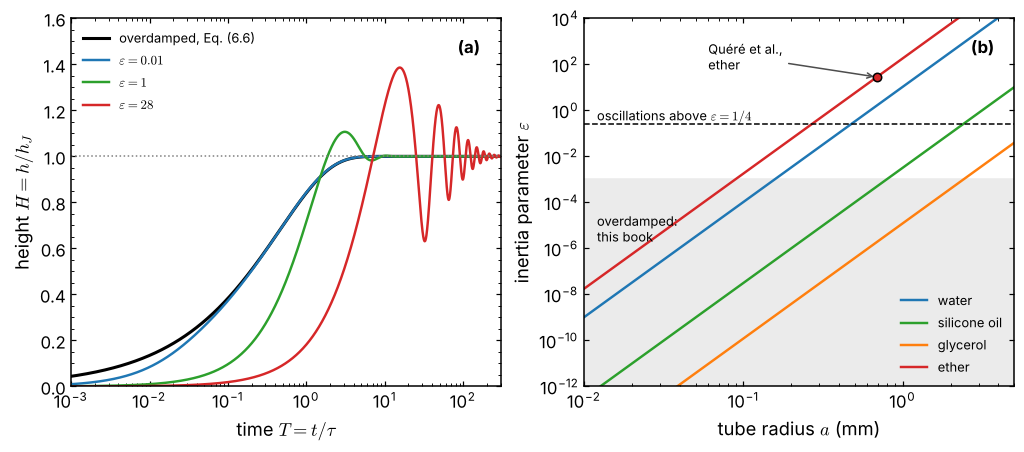

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 4.0))

T_show = np.concatenate(([0.0], np.geomspace(1e-4, 300, 6000)))
ax1.semilogx(T_show[1:], overdamped(T_show)[1:], "k-", lw=2, label=r"overdamped, Eq. (6.6)")
for eps, col in ((0.01, "C0"), (1.0, "C2"), (eps_ether, "C3")):
    ax1.semilogx(T_show[1:], bosanquet(eps, T_show)[1:], color=col, label=rf"$\varepsilon = {eps:.2g}$")
ax1.axhline(1, color="0.5", ls=":", lw=1)
ax1.set_xlim(1e-3, 300)
ax1.set_xlabel(r"time $T = t/\tau$"); ax1.set_ylabel(r"height $H = h/h_J$")
ax1.set_ylim(0, 1.6); ax1.legend(loc="upper left", fontsize=8.5); on.panel_label(ax1, "(a)", x=0.9, y=0.95)

radii = np.logspace(-5, -2.3, 200)
for (name, (rho, eta, gamma)), col in zip({**liquids, "ether": (710.0, 3e-4, 0.0166)}.items(), ("C0", "C2", "C1", "C3")):
    ax2.loglog(1e3 * radii, eps_param(rho, eta, gamma, radii), color=col, label=name)
ax2.axhline(0.25, color="k", ls="--", lw=1)
ax2.text(0.012, 0.36, r"oscillations above $\varepsilon = 1/4$", fontsize=8.5)
ax2.axhspan(1e-14, 1e-3, color="0.92")
ax2.text(0.012, 2e-6, "overdamped:\nthis book", fontsize=8.5)
ax2.plot(0.689, eps_ether, "o", color="C3", mec="k", zorder=5)
ax2.annotate("Quéré et al.,\nether", xy=(0.689, eps_ether), xytext=(0.06, 60), fontsize=8.5, arrowprops=dict(arrowstyle="->", color="0.3"))
ax2.set_xlim(0.01, 5); ax2.set_ylim(1e-12, 1e4)
ax2.set_xlabel("tube radius $a$ (mm)"); ax2.set_ylabel(r"inertia parameter $\varepsilon$")
ax2.legend(loc="lower right", fontsize=8.5); on.panel_label(ax2, "(b)", x=0.9, y=0.95)
plt.show()

**Figure 6.2.** **(a)** Rise with inertia, Eq. (6.8), compared with the overdamped
law of the Onsager principle (logarithmic time axis). For small $\varepsilon$ the two
coincide except at the very start; at $\varepsilon = 1$ the column overshoots slightly;
at the value for ether in the experiment of Quéré and co-workers it rises at nearly
constant speed, overshoots by about 40 % and oscillates before settling. **(b)** The inertia parameter as a function of the tube radius for four
liquids. It rises as $a^5$. In the grey region (below $10^{-3}$) the overdamped
description is accurate to better than 1 % of the Jurin height; for water this
covers tubes up to about 0.16 mm in radius, for glycerol tubes up to about 2.4 mm.

## 6.5 Imbibition into a porous material

A paper strip, a sponge or a bed of sand is a network of narrow channels. When it
touches a liquid, the liquid is drawn in just as into a tube, and the same two
functions apply with the tube replaced by an averaged porous medium. Let $L(t)$ be
the length wetted, $\phi$ the porosity (the volume fraction of pores), $\kappa$ the
permeability and $p_c$ the capillary pressure that draws the liquid in.

* The free energy decreases by $p_c\phi$ per unit volume of material wetted: $A = -p_c\phi L$
  per unit cross-section.
* The liquid moves through the pores with velocity $\dot L$, which corresponds to a
  Darcy (superficial) velocity $\phi\dot L$. From Section 4.5, the dissipation per unit
  cross-section is $\Phi = \tfrac12(\eta/\kappa)(\phi\dot L)^2L$.

Minimising $\Phi + \dot A$ gives $(\eta\phi^2/\kappa)\,L\dot L = p_c\phi$, so

$$ L^2 = \frac{2\kappa p_c}{\eta\phi}\,t . \tag{6.9} $$

The Lucas–Washburn law holds for porous materials as well, with a coefficient that
combines the capillary pressure and the permeability of the material. Measuring
$L^2/t$ for a liquid of known properties is a standard way of characterising the
pores. Exercise 2 shows that for a bundle of identical tubes Eq. (6.9) reduces to
Eq. (6.5), as it must.

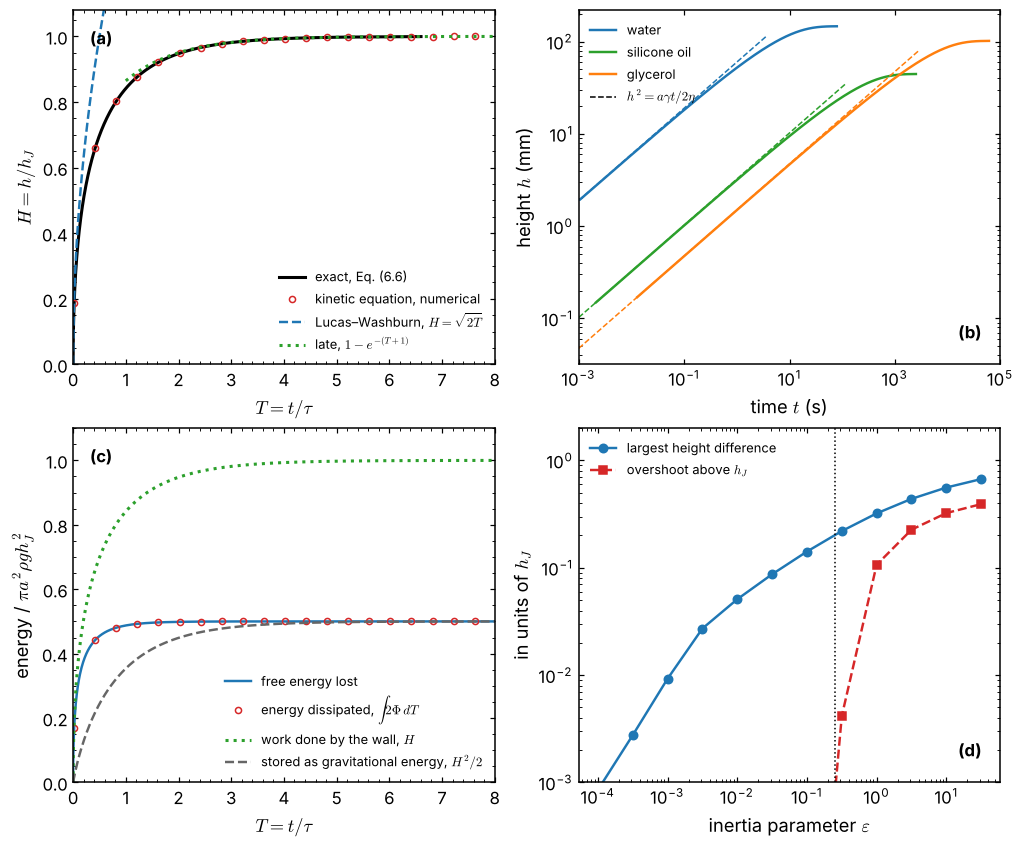

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))

ax = axes[0, 0]
Hs = np.linspace(0, 0.9995, 600)
ax.plot(T_of_H(Hs), Hs, "k-", lw=2, label="exact, Eq. (6.6)")
ax.plot(T_num[200::40], Hk[200::40], "o", color="C3", mfc="none", ms=4, label="kinetic equation, numerical")
Tw = np.linspace(0, 1.2, 100)
ax.plot(Tw, np.sqrt(2 * Tw), "--", color="C0", label=r"Lucas–Washburn, $H = \sqrt{2T}$")
Tl = np.linspace(1, 8, 100)
ax.plot(Tl, 1 - np.exp(-(Tl + 1)), ":", color="C2", lw=2, label=r"late, $1 - e^{-(T+1)}$")
ax.set_xlim(0, 8); ax.set_ylim(0, 1.08)
ax.set_xlabel(r"$T = t/\tau$"); ax.set_ylabel(r"$H = h/h_J$"); ax.legend(loc="lower right", fontsize=8.5)
on.panel_label(ax, "(a)", x=0.04, y=0.95)

ax = axes[0, 1]
for (name, (rho, eta, gamma)), col in zip(liquids.items(), ("C0", "C2", "C1")):
    hJ, tau = jurin(rho, eta, gamma, a)
    t_real = tau * T_of_H(Hs)
    keep = t_real > 1e-3
    ax.loglog(t_real[keep], 1e3 * hJ * Hs[keep], color=col, label=name)
    tw = np.logspace(-3, math.log10(tau * 0.3), 50)
    ax.loglog(tw, 1e3 * np.sqrt(a * gamma * tw / (2 * eta)), "--", color=col, lw=1)
ax.plot([], [], "k--", lw=1, label=r"$h^2 = a\gamma t/2\eta$")
ax.set_xlabel("time $t$ (s)"); ax.set_ylabel("height $h$ (mm)"); ax.set_xlim(1e-3, 1e5)
ax.legend(loc="upper left", fontsize=8.5); on.panel_label(ax, "(b)", x=0.9, y=0.12)

ax = axes[1, 0]
ax.plot(T_num, A_k[0] - A_k, color="C0", label="free energy lost")
ax.plot(T_num[200::40], dissipated[200::40], "o", color="C3", mfc="none", ms=4, label=r"energy dissipated, $\int 2\Phi\,dT$")
ax.plot(T_num, Hk, ":", color="C2", lw=2, label=r"work done by the wall, $H$")
ax.plot(T_num, 0.5 * Hk**2, "--", color="0.4", label=r"stored as gravitational energy, $H^2/2$")
ax.set_xlabel(r"$T = t/\tau$"); ax.set_ylabel(r"energy / $\pi a^2\rho g h_J^2$")
ax.set_xlim(0, 8); ax.set_ylim(0, 1.1)
ax.legend(loc="lower right", fontsize=8.5); on.panel_label(ax, "(c)", x=0.04, y=0.95)

ax = axes[1, 1]
ax.loglog(eps_values, gap, "o-", color="C0", label="largest height difference")
ax.loglog(eps_values, np.maximum(overshoot, 1e-6), "s--", color="C3", label="overshoot above $h_J$")
ax.axvline(0.25, color="k", ls=":", lw=1)
ax.set_ylim(1e-3, 2)
ax.set_xlabel(r"inertia parameter $\varepsilon$"); ax.set_ylabel(r"in units of $h_J$")
ax.legend(loc="upper left", fontsize=8.5); on.panel_label(ax, "(d)", x=0.9, y=0.12)
plt.show()

**Figure 6.3.** **(a)** Every capillary rise in the overdamped regime follows one
curve: the exact solution (6.6), the numerical solution of the kinetic equation,
the Lucas–Washburn law at early times and the exponential approach at late times.
**(b)** The same curve in real units for three liquids in a tube of radius 0.1 mm;
the dashed lines are Eq. (6.5). **(c)** Energy balance: the wall does work $H$; half
of it is stored as gravitational energy, and the other half, which is the free
energy lost, is dissipated. **(d)** Difference between
the inertial and the overdamped solutions as a function of $\varepsilon$; the column
overshoots only above $\varepsilon = \tfrac14$.

## Summary

* With one variable, the height $h$, the free energy is a wetting term that falls
  linearly and a gravitational term that rises quadratically, and the dissipation is
  a Poiseuille flow over the filled length.
* Minimising the Rayleighian gives the Lucas–Washburn law $h^2 = (a\gamma\cos\theta/2\eta)\,t$
  at early times and Jurin's height $h_J = 2\gamma\cos\theta/\rho g a$ at the end, with
  the exact intermediate solution $t/\tau = -H - \ln(1 - H)$.
* Half of the work done by the wall is stored as gravitational energy and half is
  dissipated, for any liquid.
* The overdamped description holds when the inertia parameter
  $\varepsilon = \rho^3g^2a^5/128\eta^2\gamma\cos\theta$ is small; above $\varepsilon = \tfrac14$ the
  column oscillates about the Jurin height.
* The same calculation for a porous material gives $L^2 = (2\kappa p_c/\eta\phi)\,t$.

## Exercises

Sample solutions are in [`solutions/part2_liquids_interfaces/06_solutions.ipynb`](../../solutions/part2_liquids_interfaces/06_solutions.ipynb).

1. **Between two plates.** A liquid rises between two parallel vertical plates a
   distance $2b$ apart. Using the second table of Section 3.2, show that the
   equilibrium height is $h_J = \gamma\cos\theta/\rho g b$ and that at early times
   $h^2 = (2b\gamma\cos\theta/3\eta)\,t$. Compare with a tube of radius $b$.
2. **A bundle of tubes.** A porous material is modelled as $n$ identical parallel tubes
   of radius $a$ per unit cross-section. Find $\phi$, $\kappa$ (from Poiseuille's law)
   and $p_c$ in terms of $n$, $a$, $\gamma$ and $\theta$, and show that Eq. (6.9) reduces to
   Eq. (6.5). Then take tubes of two radii, $a$ and $2a$, in equal numbers: which
   tubes fill faster, and is the total uptake still proportional to $\sqrt t$?
3. **Oscillations.** Linearise Eq. (6.8) about $H = 1$ and show that the column
   oscillates when $\varepsilon > \tfrac14$, with angular frequency
   $\omega = \sqrt{4\varepsilon - 1}/2\varepsilon$ in units of $1/\tau$. Compare the period with the
   numerical solution for $\varepsilon = 28$, and express it in seconds for the
   experiment of Quéré and co-workers.
4. **Friction at the contact line.** Add the dissipation of a moving contact line,
   $\Phi_{\rm cl} = \tfrac12\xi_{\rm cl}\,(2\pi a)\,\dot h^2$ (Section 3.2), and neglect gravity. Show
   that the rise is linear in time, $h \approx (\gamma\cos\theta/\xi_{\rm cl})\,t$, while $h$ is
   shorter than $\ell = a\xi_{\rm cl}/4\eta$, and follows the Lucas–Washburn law beyond.
   Find the exact $h(t)$.

## Suggested references

* P.-G. de Gennes, F. Brochard-Wyart and D. Quéré, *Capillarity and Wetting Phenomena* (Springer, 2004).
* M. Doi, *Soft Matter Physics* (Oxford University Press, 2013).
* R. Lucas, "Ueber das Zeitgesetz des kapillaren Aufstiegs von Flüssigkeiten", *Kolloid-Z.* **23**, 15 (1918).
* E. W. Washburn, "The dynamics of capillary flow", *Phys. Rev.* **17**, 273 (1921).
* C. H. Bosanquet, "On the flow of liquids into capillary tubes", *Phil. Mag.* **45**, 525 (1923).
* D. Quéré, "Inertial capillarity", *Europhys. Lett.* **39**, 533 (1997).
* D. Quéré, É. Raphaël and J.-Y. Ollitrault, "Rebounds in a capillary tube", *Langmuir* **15**, 3679 (1999).

---

**Previous:** [5. The approximation method](../part1_principle/05_approximation_method.ipynb) &nbsp;·&nbsp; **Next:** [7. Spreading of a droplet](07_spreading_droplet.ipynb)